# 05 · The agent loop, written by hand, with step and cost caps
Level L2 · Part 2 · core · ~30 min · builds on 04

## Goal
Write the agent loop yourself: call the model, run the tools it asks for, send the results back, and stop. The loop ends on an
answer or on one of three stops: the step cap, the spend cap or a repeated call. Each stop prints its reason. Two stops fire
live in the recorded runs: answered and repeated call. The step cap and the spend cap are checked on the same recorded numbers,
with no model call. A short graph at the end shows the step cap as a counter in the state.

## Why it matters
One model call and one tool call is a round trip. An agent repeats the round trip, and nothing in the model stops it. A model that
keeps asking for the same lookup keeps you paying, and the customer still gets no answer.

```python
while True:
    reply = model(messages)          # every pass is a paid call
    if not reply.tool_requests:
        break                        # the only exit: the model says it is done
    messages += run_tools(reply)     # the model asks for the same lookup forever?
```

One step with 1,000 input and 100 output tokens costs about $0.0004; 10,000 stuck steps cost about $4.

**What it makes easy:** one place for the limits, and a stop reason you can log. **When you don't need it:** a fixed two-call
workflow has nothing to cap.

## The idea
An agent loop is a `while` loop with exits. Each pass, the model either answers (the loop ends) or asks for tools. Your code
checks the caps, runs the tools it asked for, and sends the results back with the model's own turn.

Three stop rules keep it bounded: the **step cap** counts model calls, the **spend cap** adds up the money from each reply's
usage, and **repeated-call detection** stops when the same tool gets the same arguments again.

Analogy: a cook with a timer, a food budget and a rule against fetching the same ingredient twice.

## Picture
The loop, as the flowchart it is. Amber is the model call; blue is code. The caps are checked before any tool runs.
`show_mermaid` is a course helper that draws a Mermaid flowchart from text; it makes no model call.

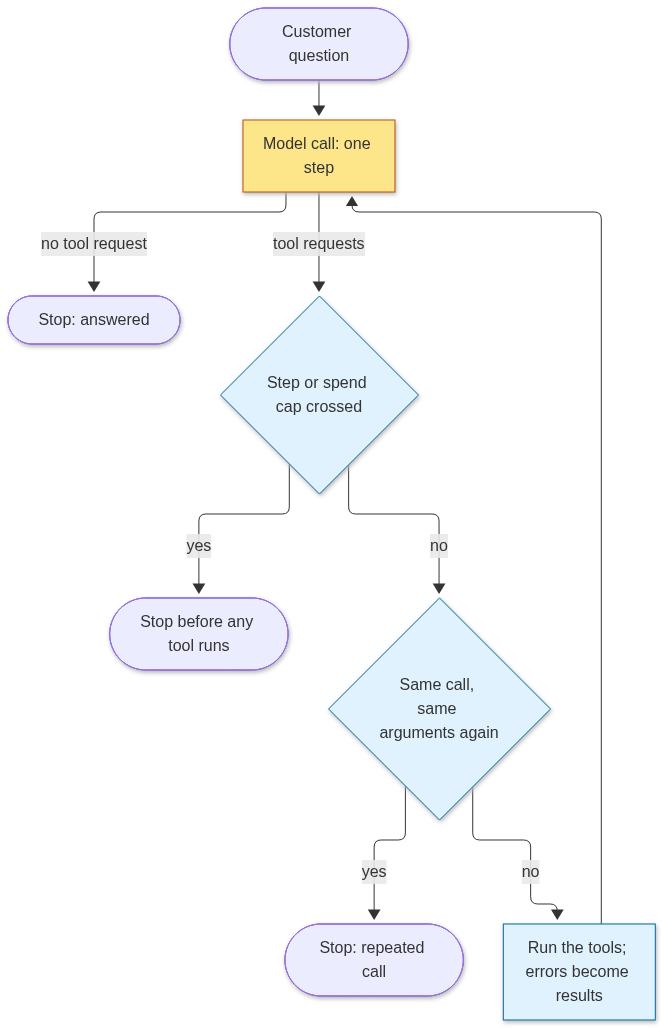

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart TD
  Q(["Customer question"]) --> M["Model call: one step"]
  M -->|no tool request| A(["Stop: answered"])
  M -->|tool requests| C{"Step or spend cap crossed"}
  C -->|yes| S(["Stop before any tool runs"])
  C -->|no| R{"Same call, same arguments again"}
  R -->|yes| D(["Stop: repeated call"])
  R -->|no| T["Run the tools; errors become results"]
  T --> M
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class C,R,T code
""")

## Step by step
**Step 1 · the tool and its registry (no call).** `lookup_order` reads a small table of made-up orders. `run_tool` checks the
arguments with the schema before it runs the function, so a bad argument becomes a readable error, not a crash. In the schema,
`extra="forbid"` rejects any key it does not name, and `model_dump()` turns the checked object back into a plain dict for the function.

In [2]:
import json
from collections import Counter
from dataclasses import dataclass, field

from pydantic import BaseModel, ConfigDict, Field, ValidationError

ORDERS = {"1093": {"status": "in transit", "days_late": 3}, "2207": {"status": "delivered", "days_late": 0}}


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote, digits only, such as 1093.")


def lookup_order(order_id: str) -> dict:
    """Look up one order: its status and days late."""
    return ORDERS.get(order_id, {"error": f"no order with id {order_id}"})


REGISTRY = {"lookup_order": (lookup_order, OrderQuery)}  # name -> (function, argument schema)


def run_tool(name: str, args: dict) -> dict:
    fn, schema = REGISTRY[name]
    checked = schema.model_validate(args).model_dump()  # refuses bad arguments before the function runs
    return fn(**checked)


print(run_tool("lookup_order", {"order_id": "1093"}))

{'status': 'in transit', 'days_late': 3}


**Common mistake 1 in code: a bad argument.** This call adds a key the schema does not name. The `try` prints only the error
type and its first message line, not the traceback. Step 4 catches the same kind of error inside the loop.

In [3]:
try:
    run_tool("lookup_order", {"order_id": "1093", "limit": 5})  # "limit" is not a key OrderQuery names
except ValidationError as error:
    print(type(error).__name__, "-", error.errors()[0]["msg"])

ValidationError - Extra inputs are not permitted


**Step 2 · the caps and the price (no call).** `Caps` holds the three limits, `Run` records what one task did, and `cost_of`
turns one reply's usage into dollars. Nothing in this cell calls the model.

In [4]:
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

PRICE_IN, PRICE_OUT = 0.25, 1.50  # USD per 1M tokens, the same as lesson 02


@dataclass
class Caps:
    max_steps: int = 6          # the step cap: model calls per task
    max_usd: float = 0.01       # the spend cap: money per task
    max_same_calls: int = 1     # repeated-call detection: the same call may run this many times


@dataclass
class Run:
    answer: str = ""
    stop: str = ""                                    # why the loop ended
    steps: int = 0                                    # model calls made
    usd: float = 0.0                                  # money spent so far
    asked: list = field(default_factory=list)         # every tool request the model made


def cost_of(reply: AIMessage) -> float:
    u = reply.usage_metadata  # the usage the reply already carries: no extra request
    return (u["input_tokens"] * PRICE_IN + u["output_tokens"] * PRICE_OUT) / 1_000_000

**Step 2 (continued) · the model (needs the model, replays offline).** `llm_replay` is a course helper: the first run records
the model's answers and later runs replay them, so the notebook works with no key. `get_llm` is the course's shared model setup.
The model's tools are bound so it may ask for `lookup_order`.

In [5]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("05_agent-loop-by-hand")

from llm_setup import get_llm  # course helper: the shared model setup

llm = get_llm()
# the model's schema: the extra-keys rule is kept by run_tool, not sent to the model
ARGS = {k: v for k, v in OrderQuery.model_json_schema().items() if k != "additionalProperties"}
model = llm.bind_tools([{"name": "lookup_order", "description": "Look up one order: status and days late.",
                         "parameters": ARGS}])

LLM mode: replay (05_agent-loop-by-hand.yaml)


Gemini on Vertex AI · API key loaded: True


**Step 3 · the stop checks and the printout (no call).** `cap_stop` checks the two number caps. It runs after each reply and
before any tool runs, and returns the stop reason, or an empty string to keep going. `show` prints a run: its stop reason,
model calls, spend and the tool requests the model made.

In [6]:
def cap_stop(run: Run, caps: Caps) -> str:
    if run.steps >= caps.max_steps:
        return "step cap"
    if run.usd > caps.max_usd:
        return "spend cap"
    return ""


def show(run: Run) -> None:
    print(f"stop: {run.stop} · model calls: {run.steps} · spent ${run.usd:.6f}")
    for call in run.asked:
        print("  model asked:", call)
    if run.answer:
        print("answer:", run.answer)

**Step 4 · the loop (the one loop you write by hand, no call yet).** Each pass is one model call. If the reply has no tool
request, the loop returns the answer. Otherwise it checks the caps, then runs the requests. A repeated request stops the loop
before it runs. A tool error becomes a result the model can read.

In [7]:
def agent_loop(question: str, caps: Caps) -> Run:
    run, counts, messages = Run(), Counter(), [HumanMessage(content=question)]
    while True:
        reply = model.invoke(messages)  # one step: one model call
        run.steps += 1
        run.usd += cost_of(reply)
        if not reply.tool_calls:
            run.answer, run.stop = reply.text, "answered"
            return run
        run.asked += [f"{c['name']} {json.dumps(c['args'], sort_keys=True)}" for c in reply.tool_calls]
        run.stop = cap_stop(run, caps)
        if run.stop:
            return run
        messages.append(reply)  # the model's own turn, unchanged
        for c in reply.tool_calls:
            key = (c["name"], json.dumps(c["args"], sort_keys=True))
            counts[key] += 1
            if counts[key] > caps.max_same_calls:
                run.stop = "repeated call"
                return run
            try:
                out = run_tool(c["name"], c["args"])
            except Exception as error:  # a bad call becomes a result the model can read, not a crash
                out = {"error": str(error).splitlines()[0]}
            messages.append(ToolMessage(content=json.dumps(out), tool_call_id=c["id"]))

**Step 5 · run 1, the normal case (2 model calls).** The question asks for two orders. The first reply asks for both lookups,
the tools run, and the second reply answers. The `spent` value on the first line is what this run cost, summed from the usage
of its two replies.

In [8]:
run1 = agent_loop("Where are my orders 1093 and 2207? Check both, then answer in two sentences.", Caps())
show(run1)

stop: answered · model calls: 2 · spent $0.000156
  model asked: lookup_order {"order_id": "1093"}
  model asked: lookup_order {"order_id": "2207"}
answer: Order 1093 is currently in transit and is three days late. Order 2207 has been successfully delivered.


**Step 6 · run 2, a model that asks for the same call again (repeated-call detection, 2 model calls).** The customer asks for a
second confirmation. The loop runs the first request, sees the second is the same call, and stops without running it.

In [9]:
run2 = agent_loop("Look up order 1093. Then look it up a second time to confirm the status has not changed, and tell me the status.",
                  Caps())
show(run2)
llm_replay.stop()  # the last model call of this lesson

stop: repeated call · model calls: 2 · spent $0.000111
  model asked: lookup_order {"order_id": "1093"}
  model asked: lookup_order {"order_id": "1093"}


**Step 7 · the step cap and the spend cap, with no model call.** Runs 1 and 2 are the only live runs, so these two stops are
checked here on run 1's numbers: 2 model calls and $0.000156 spent. This cell needs no key, because `cap_stop` only compares numbers.

In [10]:
# run 1's numbers from the output above: 2 model calls, $0.000156
print("max_steps=1 ->", repr(cap_stop(Run(steps=2), Caps(max_steps=1))))
print("max_usd=0.0001 ->", repr(cap_stop(Run(steps=2, usd=0.000156), Caps(max_usd=0.0001))))
print("defaults ->", repr(cap_stop(Run(steps=2, usd=0.000156), Caps())))

max_steps=1 -> 'step cap'
max_usd=0.0001 -> 'spend cap'
defaults -> ''


## The same loop as a graph
The same loop as a LangGraph graph: a model node, a router, a tools node and a cap node. The step cap here is a counter in the
state (`steps >= 3` in the router), not LangGraph's `recursion_limit`, and the spend and repeat checks are left out. Lesson 11
builds this graph with all three stops. `show_graph` is a course helper that draws the graph; it makes no model call.

In [11]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain_core.tools import tool


class LoopState(TypedDict):
    messages: Annotated[list, add_messages]
    steps: int
    stop: str


def model_step(state: LoopState) -> dict:
    reply = model.invoke(state["messages"])
    return {"messages": [reply], "steps": state["steps"] + 1, "stop": "" if reply.tool_calls else "answered"}


def route(state: LoopState) -> Literal["tools", "cap", "__end__"]:
    if not state["messages"][-1].tool_calls:
        return END
    return "cap" if state["steps"] >= 3 else "tools"


def cap(state: LoopState) -> dict:
    return {"stop": "step cap: the requested tools did not run"}

The nodes and the state are above. The next cell adds the edges and draws the graph.

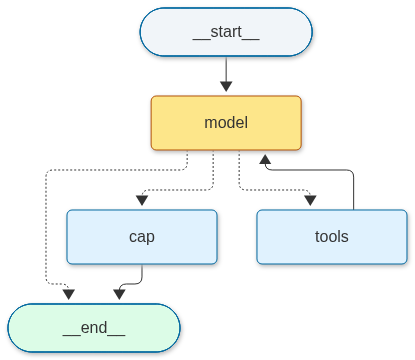

In [12]:
loop_graph = StateGraph(LoopState)
loop_graph.add_node("model", model_step)
loop_graph.add_node("tools", ToolNode([tool(lookup_order)]))
loop_graph.add_node("cap", cap)
loop_graph.add_edge(START, "model")
loop_graph.add_conditional_edges("model", route, {"tools": "tools", "cap": "cap", END: END})
loop_graph.add_edge("tools", "model").add_edge("cap", END)
loop_app = loop_graph.compile()

from graph_view import show_graph
show_graph(loop_app, model_nodes=("model",))

## At work
- Production agents set a step cap, a spend limit per task and a stop reason, and log the reason with the trace. A stop nobody
  can see looks like a slow answer → lesson 25 (observability) and lesson 36 (cost caps).
- A repeated step is a named failure. Teams use a repeated-call check and a loop limit, and test both → lesson 22 (failure modes).
- A timeout or a busy-server error inside the loop needs a retry with backoff, not a crash that loses the trace → lesson 35.

## What just happened
- Run 1 printed `stop: answered · model calls: 2 · spent $0.000156`: two replies and two lookups, and the spend added up from
  the usage of both replies.
- Run 2 printed `stop: repeated call` after 2 model calls. The model asked for order 1093 twice, and the second lookup never ran.
- Step 7 printed `'step cap'` for `max_steps=1`, `'spend cap'` for `max_usd=0.0001`, and `''` (no stop) for the defaults,
  on run 1's numbers.
- The graph cell only drew the picture. Its step cap is a counter in the state, and it made no model call.

## Common mistakes
1. **A bad argument ends the task.** The loop catches the error and returns it as a result, so the model can correct the call.
   Without that `try`, the whole run stops with no answer and no trace. The error itself is shown in Step 1 above.
2. **Checking the spend only once.** Money is spent on each reply, so check after each reply. A check before the first call sees
   $0 every time and never fires. Fix: run `cap_stop` after every reply, as Step 4 does.
3. **Counting only tool calls.** A step is a model call. A reply that asks for three tools is still one step. Fix: count
   `run.steps` once per reply, as Step 4 does.

## Try it
Write `is_repeat(counts, key, max_same)` that returns `True` when `counts[key]` is more than `max_same`. Check it on three cases:
seen once with `max_same=1`, seen twice with `max_same=1`, and seen twice with `max_same=2`. No model call is needed.

In [13]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [14]:
def is_repeat(counts: Counter, key, max_same: int) -> bool:
    return counts[key] > max_same


key = ("lookup_order", '{"order_id": "1093"}')
print(is_repeat(Counter({key: 1}), key, 1), is_repeat(Counter({key: 2}), key, 1), is_repeat(Counter({key: 2}), key, 2))  # False True False

False True False


## Key terms
- **Step cap** — the most model calls one task may make before the loop stops.
- **Spend cap** — the most money one task may cost, added up from each reply's usage and checked after each reply.
- **Repeated-call detection** — stops the loop when the model asks for the same tool with the same arguments again.
- **Stop reason** — the one-word reason a loop ended (`answered`, `step cap`, `spend cap`, `repeated call`), logged with the run.
- **`extra="forbid"`** — a pydantic setting that rejects any argument key the schema does not name.

## Recap
- An agent loop stops on an answer, a step cap, a spend cap or a repeated call. Each stop returns a reason.
- The step cap counts model calls; the spend cap adds up each reply's usage. Both are checked before any tool runs.
- A bad tool call becomes a result the model can read, so one error does not end the task.
- The graph draws the same loop; lesson 11 builds it with all three stops.

**Interview:** "An agent loops forever on one customer. How do you stop it, and what do you log?" Strong answer: "I cap model calls
and spend per task, and stop when the same tool call repeats. Each stop logs its reason, and a tool error goes back to the model as a result."